In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
from sqlalchemy import create_engine
import lightgbm as lgb
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_validate
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, f1_score, recall_score, precision_score
import shap
import sklearn

In [2]:
# 1. 解决中文乱码和负号显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 用黑体
plt.rcParams['axes.unicode_minus'] = False

In [3]:
from sqlalchemy import create_engine

# 1. 根据你的截图填写的配置
DB_USER = 'root'
DB_PASS = '123456'        # 👈 这里填你安装 MySQL 时设置的 root 密码
DB_HOST = 'localhost'      # 主机
DB_PORT = '3306'           # 端口
DB_NAME = 'EAI'     # 👈 这里填你的表所在的“数据库”名称

# 2. 创建连接引擎
engine = create_engine(f'mysql+pymysql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}?charset=utf8mb4')

# 3. 读取表数据
sql_query = "SELECT * FROM `电子商务客户流失数据`"
df = pd.read_sql(sql_query, con=engine)

print(f"数据读取成功！维度: {df.shape}")
print(df.head())

数据读取成功！维度: (50000, 35)
         流失记录ID         客户ID   客户细分   客户国家  客户城市 是否已流失  流失标志        流失日期  \
0  CHURN-000001  CUST-020712  个人消费者   澳大利亚  布里斯班     1     1  2026-05-18   
1  CHURN-000002  CUST-044206   小型企业  沙特阿拉伯   胡拜尔     0     0         不适用   
2  CHURN-000003  CUST-024093   小型企业    墨西哥    莱昂     0     0         不适用   
3  CHURN-000004  CUST-037777   企业客户  沙特阿拉伯    吉达     0     0         不适用   
4  CHURN-000005  CUST-016248   高端客户   巴基斯坦   木尔坦     1     1  2026-05-28   

   流失至今天数   流失原因  ... 反馈评分 忠诚度评分  营销邮件发送数  营销邮件打开数  营销邮件点击数  营销转化数  社交媒体参与度  \
0      23  找到替代品  ...    1  85.5       26        8       22      7        无   
1       0    不适用  ...    8  23.3       17       10       14      2        低   
2       0    不适用  ...   10  58.2       27       25        4      2        低   
3       0    不适用  ...    6  38.8       48       38       48      6       中等   
4       7  客户服务差  ...    6  34.3       39       14       17      3        高   

  推荐次数  数据集年份  客户价值类别  
0    4   2026     高价值

In [4]:
df.columns   

Index(['流失记录ID', '客户ID', '客户细分', '客户国家', '客户城市', '是否已流失', '流失标志', '流失日期',
       '流失至今天数', '流失原因', '流失类别', '订阅类型', '客户存续月数', '总消费金额(美元)', '平均订单金额(美元)',
       '购买次数', '满意度评分', '满意度等级', '客服工单数', '退货次数', '距上次购买天数', '客户终身价值(美元)',
       '参与度水平', '客服互动次数', '最近客服渠道', '反馈评分', '忠诚度评分', '营销邮件发送数', '营销邮件打开数',
       '营销邮件点击数', '营销转化数', '社交媒体参与度', '推荐次数', '数据集年份', '客户价值类别'],
      dtype='str')

In [5]:
df.dtypes    

流失记录ID            str
客户ID              str
客户细分              str
客户国家              str
客户城市              str
是否已流失             str
流失标志            int64
流失日期              str
流失至今天数          int64
流失原因              str
流失类别              str
订阅类型              str
客户存续月数          int64
总消费金额(美元)     float64
平均订单金额(美元)    float64
购买次数            int64
满意度评分           int64
满意度等级             str
客服工单数           int64
退货次数            int64
距上次购买天数         int64
客户终身价值(美元)    float64
参与度水平             str
客服互动次数          int64
最近客服渠道            str
反馈评分            int64
忠诚度评分         float64
营销邮件发送数         int64
营销邮件打开数         int64
营销邮件点击数         int64
营销转化数           int64
社交媒体参与度           str
推荐次数            int64
数据集年份           int64
客户价值类别            str
dtype: object

In [6]:
df["是否已流失"] = df["是否已流失"].astype(int)

In [7]:
D = df[[ '客户存续月数', '总消费金额(美元)', '购买次数', '满意度评分', '客服工单数',  '退货次数', '距上次购买天数', '客户终身价值(美元)', '客服互动次数', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', '营销转化数', '推荐次数']]


数值特征相关性热力图


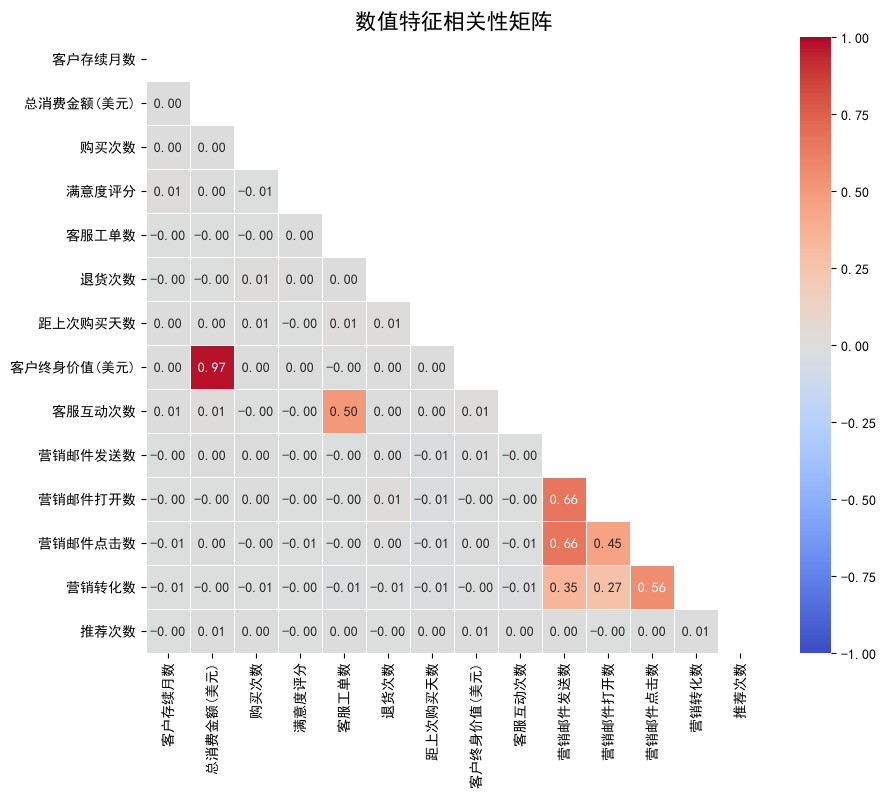

In [8]:
# 2. 确保至少有2个以上的特征才能画相关性热力图
if D.shape[1] > 1: 
    print("\n" + "=" * 60)
    print("数值特征相关性热力图")
    
    plt.figure(figsize=(10, 8))
    
    # 3. 对 D 计算相关系数
    corr_matrix = D.corr(method='spearman') # 建议用 spearman 防长尾干扰
    
    # 4. 画出热力图 (只显示上半三角)
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
                cmap='coolwarm', vmin=-1, vmax=1, center=0,
                square=True, linewidths=.5)
    
    plt.title('数值特征相关性矩阵', fontsize=16)
    plt.show()

In [9]:
features = ['客户存续月数', '总消费金额(美元)', '购买次数', '满意度评分', '客服工单数', '退货次数', 
            '距上次购买天数', '客服互动次数', '营销邮件发送数', '营销邮件打开数', '营销邮件点击数', 
            '营销转化数', '推荐次数']
X = df[features]
Y = df['是否已流失']

In [10]:
value_weights = {'高价值': 10.0, '中价值': 3.0, '低价值': 1.0, '极低价值': 0.5}
df['样本权重'] = df['客户价值类别'].map(value_weights).fillna(1.0)

In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)
train_weights = df.loc[X_train.index, '样本权重']

In [12]:
# 计算正负样本失衡比例 (如果要在 LightGBM/XGBoost 用)
neg_count = (Y_train == 0).sum()
pos_count = (Y_train == 1).sum()
scale_weight = neg_count / pos_count if pos_count > 0 else 1.0


In [13]:
scale_weight 

np.float64(1.4131274131274132)

In [14]:
model_dict = {
    "LightGBM": {
        "model": lgb.LGBMClassifier(random_state=42, verbose=-1, scale_pos_weight=scale_weight),
        "params": {
            'n_estimators': [100, 200, 300],
            'learning_rate': [0.01, 0.05, 0.1],
            'num_leaves': [15, 31, 63],
            'min_child_samples': [10, 20, 50],
            'subsample': [0.7, 0.9, 1.0],
            'colsample_bytree': [0.7, 0.9, 1.0],
            'reg_alpha': [0, 0.1, 1],
            'reg_lambda': [1, 2, 5]
        }
    },
    "XGBoost": {
        "model": xgb.XGBClassifier(random_state=42, eval_metric='logloss',  scale_pos_weight=scale_weight),
        "params": {
            'n_estimators': [100, 200, 300],
            'learning_rate': [0.01, 0.05, 0.1],
            'max_depth': [3, 5, 7],
            'min_child_weight': [1, 3, 5],      # XGB 特有的叶子最小权重
            'subsample': [0.7, 0.9, 1.0],
            'colsample_bytree': [0.7, 0.9, 1.0],
            'reg_alpha': [0, 0.1, 1],
            'reg_lambda': [1, 2, 5]
        }
    },
    "RandomForest": {
        "model": RandomForestClassifier(random_state=42, class_weight='balanced'),
        "params": {
            'n_estimators': [100, 200, 300],
            'max_depth': [5, 10, 15],
            'min_samples_split': [2, 5, 10],    # 节点分裂最小样本数
            'min_samples_leaf': [10, 20, 50],
            'max_features': ['sqrt', 'log2', 0.8] # 随机森林的核心：特征采样
        }
    },
    "DecisionTree": {
        "model": DecisionTreeClassifier(random_state=42, class_weight='balanced'),
        "params": {
            'max_depth': [3, 5, 7, 10],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [20, 50, 100],
            'criterion': ['gini', 'entropy'],   # 评价标准：基尼系数 vs 信息熵
            'ccp_alpha': [0.0, 0.001, 0.01]     # 决策树后剪枝参数
        }
    }
}

In [15]:
results = []
best_models = {}

print("开始多模型PK对决...\n")

for name, config in model_dict.items():
    print(f"⏳ 正在训练和调优 [{name}] ...")
    
    # 👇 【核心修复 2】：正确的缩进，让每个模型都参与训练
    search = RandomizedSearchCV(
        config["model"],
        param_distributions=config["params"],
        n_iter=10,       # 随机搜索尝试 10 次参数组合
        cv=3,            # 3折交叉验证
        scoring='f1',    # 统一用 F1 分数寻找最优参数
        n_jobs=-1,
        random_state=42
    )
    
    # 训练
    search.fit(X_train, Y_train, sample_weight=train_weights)
    
    # 获取最优模型
    best_model = search.best_estimator_
    best_models[name] = best_model
    
    # 在测试集上预测
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]
    
    # 记录各项指标
    results.append({
        "模型名称": name,
        "准确率(Acc)": accuracy_score(Y_test, y_pred),
        "AUC": roc_auc_score(Y_test, y_pred_proba),
        "F1分数": f1_score(Y_test, y_pred),
        "精确率(Precision)": precision_score(Y_test, y_pred),
        "召回率(Recall)": recall_score(Y_test, y_pred)
    })
    print(f"[{name}] 训练完毕，当前 F1 分数: {f1_score(Y_test, y_pred):.4f}\n")

开始多模型PK对决...

⏳ 正在训练和调优 [LightGBM] ...
[LightGBM] 训练完毕，当前 F1 分数: 0.6201

⏳ 正在训练和调优 [XGBoost] ...
[XGBoost] 训练完毕，当前 F1 分数: 0.6198

⏳ 正在训练和调优 [RandomForest] ...
[RandomForest] 训练完毕，当前 F1 分数: 0.6217

⏳ 正在训练和调优 [DecisionTree] ...
[DecisionTree] 训练完毕，当前 F1 分数: 0.6248



In [16]:
results_df = pd.DataFrame(results).sort_values(by="F1分数", ascending=False)
results_df.set_index("模型名称", inplace=True)
results_df = results_df.round(4)

In [17]:
print("\n" + "="*50)
print("多模型最终评测榜单 (按 F1 分数排序)")
print("="*50)
print(results_df)


多模型最终评测榜单 (按 F1 分数排序)
              准确率(Acc)     AUC    F1分数  精确率(Precision)  召回率(Recall)
模型名称                                                               
DecisionTree    0.6419  0.7076  0.6248          0.5454       0.7312
RandomForest    0.6602  0.7171  0.6217          0.5692       0.6848
LightGBM        0.6588  0.7174  0.6201          0.5678       0.6831
XGBoost         0.6581  0.7169  0.6198          0.5669       0.6836


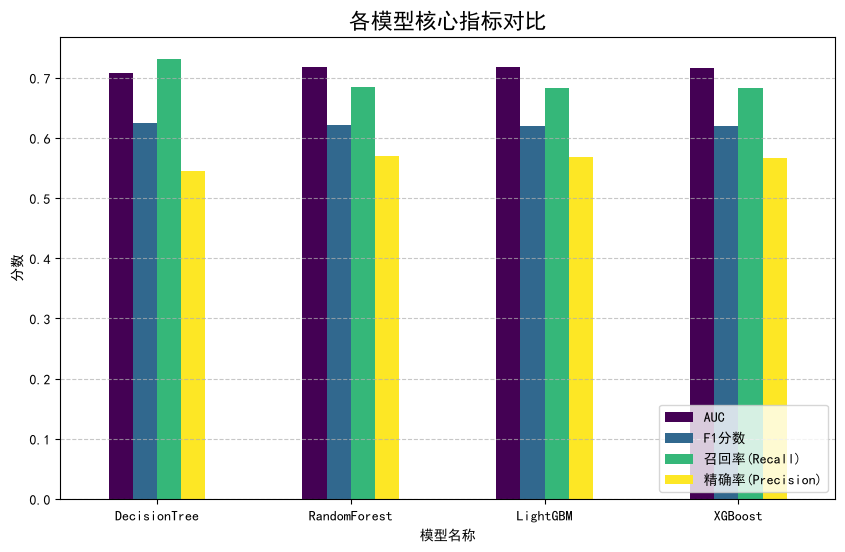

In [18]:
results_df[['AUC', 'F1分数', '召回率(Recall)', '精确率(Precision)']].plot(
    kind='bar', figsize=(10, 6), colormap='viridis'
)
plt.title('各模型核心指标对比', fontsize=16)
plt.ylabel('分数')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
champion_model = best_models['LightGBM']
print("\n最终选定模型: [LightGBM]")
print("="*40)
print("冠军模型深度交叉验证 (5折)")
print("="*40)
cv_results = cross_validate(
    estimator=champion_model, X=X_train, y=Y_train, cv=5,
    scoring=['roc_auc', 'accuracy', 'f1'], return_train_score=True, n_jobs=-1
)

mean_auc = cv_results['test_roc_auc'].mean()
mean_f1 = cv_results['test_f1'].mean()
train_auc = cv_results['train_roc_auc'].mean()
overfit_gap = train_auc - mean_auc


最终选定模型: [LightGBM]
冠军模型深度交叉验证 (5折)


In [ ]:
print(f"平均测试集 AUC: {mean_auc:.4f} | F1: {mean_f1:.4f}")
print(f"训练集 AUC: {train_auc:.4f}")
if overfit_gap > 0.05:
    print(f"过拟合警告: Gap {overfit_gap:.4f}")
else:
    print(f"泛化良好: Gap {overfit_gap:.4f}，模型稳健。")

In [ ]:
# 在测试集上做最终预测
y_pred = champion_model.predict(X_test)
y_pred_proba = champion_model.predict_proba(X_test)[:, 1]

print(f"\n最终模型在训练集的准确率: {champion_model.score(X_train, Y_train):.4f}")
print(f"最终模型在测试集的准确率: {accuracy_score(Y_test, y_pred):.4f}")
print(f"最终模型的 AUC 值: {roc_auc_score(Y_test, y_pred_proba):.4f}")
print("\n分类报告:\n", classification_report(Y_test, y_pred))

In [ ]:
# 4. 第三阶段：特征重要性与 SHAP 解析
# ==========================================
importance_df = pd.DataFrame({
    '特征': X.columns,
    '重要性': champion_model.feature_importances_
}).sort_values(by='重要性', ascending=False)
print("\n特征重要性排名:\n", importance_df.head(10))

In [ ]:
print("\n 正在生成 SHAP 解释图...")
explainer = shap.TreeExplainer(champion_model)
shap_values = explainer.shap_values(X_test)

# 全局特征重要性图（条形图）
shap.summary_plot(shap_values, X_test, plot_type="bar")
# 全局蜂群图
shap.summary_plot(shap_values, X_test)

In [ ]:
# 1. 提取全量特征
X_all = df[features]

# 2. 用最优模型预测全量概率
y_proba_all = best_model.predict_proba(X_all)[:, 1]

# 3. 直接赋值为新列
df['流失概率'] = y_proba_all

# 4. 根据概率打上风险标签
def get_risk_level(prob):
    if prob >= 0.5:
        return '高危'
    elif prob >= 0.3:
        return '中危'
    else:
        return '低危'

df['风险等级'] = df['流失概率'].apply(get_risk_level)

# 5. 按概率从高到低排序，导出给业务方
df = df.sort_values(by='流失概率', ascending=False)
df.to_excel(r'C:\Users\81599\Desktop\全量客户流失预警名单.xlsx', index=False)
print("全量名单已导出，前5名高危客户：")
print(df[['客户ID', '客户价值类别', '流失概率', '风险等级']].head())